# PRE-PROCESSING OF THE STUDENT DATASET

This Notebook explores the .csv dataset used to detect patients with pathologies.

GOALS:
- Missing value detection
- Duplicate identification
- File reorganization
- Clustering

In [234]:
import pandas as pd
import sklearn as skl
import matplotlib.pyplot as plt
import numpy as np


df = pd.read_csv('../Student_Dataset.csv')

print("Aperçu des premières lignes (df.head) :")
df

Aperçu des premières lignes (df.head) :


,1,On uneven paths the heel feels wobbly side‑to‑side. Slanted pavements bring a quick aching shift under the ankle when I step.
2,0x000000,"The feverish feeling eased, but I’m now breath..."
3,0x000000,"While working in the garden, I touched a metal..."
4,A short sprint brought on a twinge in the midd...,NaN
5,0x000000,I accidentally left my hand on a hot mug for a...
6,A sudden twist while reaching for a bag made o...,NaN
...,...,...
1007,0x000000,I slammed my fingertip in a drawer. The tip is...
1008,0x000000,I woke up with a throbbing pain in my left ear...
1009,0x000000,"During the summer, my throat gets itchy and I ..."
1010,Pushing off during a brisk walk makes the big ...,NaN


### Conclusion

We have noticed irregularities in the file. Some lines contain two columns, while others have three. There are also instances of "0x000000" and some missing data. "0x000000" codes appear in place of some testimonials. We can also say that there are tree main column in this dataset: `ID`, `Code` and `Testimonials`.

## Cleaning of the dataset

To do this, we will first replace the testimonials with the 0x000000 values. Then, we will delete the columns where testimonials are missing and any duplicates. After that, we will apply `Trimming` and then `Stemming` to the Testimonials column. The goal is to clean up all punctuation, special characters, and stop words, and to reduce the number of columns to 2.

In [235]:
df_clean = pd.read_csv('../Student_Dataset.csv', header=None, names=['ID', 'Code', 'Testimonies'], on_bad_lines='skip')

mask_decalage = ~df_clean['Code'].astype(str).str.contains('0x', na=False)
df_clean.loc[mask_decalage, 'Testimonies'] = df_clean['Code']
df_clean.loc[mask_decalage, 'Code'] = 'Unknown'

df_final = df_clean.dropna(subset=['Testimonies']).copy()
df_final = df_final.drop_duplicates(subset=['Testimonies'])

df_final['Testimonies'] = df_final['Testimonies'].str.lower()
df_final['Testimonies'] = df_final['Testimonies'].str.replace(r'[^a-z\s]', ' ', regex=True)

stop_words = ['i', 'me', 'my', 'we', 'our', 'you', 'your', 'he', 'him', 'his', 'she', 'her', 
              'it', 'its', 'they', 'them', 'their', 'a', 'an', 'the', 'and', 'but', 'is', 'are',
              'was', 'were', 'be', 'been', 'at', 'by', 'for', 'with', 'about', 'to', 'from', 'in', 'on']

for word in stop_words:
    df_final['Testimonies'] = df_final['Testimonies'].str.replace(rf'\b{word}\b', '', regex=True)

df_final['Testimonies'] = df_final['Testimonies'].str.replace(r'ing\b', '', regex=True)
df_final['Testimonies'] = df_final['Testimonies'].str.replace(r's\b', '', regex=True)
df_final['Testimonies'] = df_final['Testimonies'].str.replace(r'\s+', ' ', regex=True).str.strip()
df_final['Code'] = df_final['Code'].fillna('Unknown')

df_final.to_csv('Student_Dataset_Cleaned.csv', index=False)
df_final


,ID,Code,Testimonies
0,1,Unknown,uneven path heel feel wobbly side side slanted...
1,2,0x000000,feverish feel eased m now breath faster dry ex...
2,3,0x000000,while work garden touched metal grill that had...
3,4,Unknown,short sprint brought twinge middle of back of ...
4,5,0x000000,accidentally left hand hot mug minute now feel...
...,...,...,...
1006,1007,0x000000,slammed fingertip drawer tip throbb nail look ...
1007,1008,0x000000,woke up throbb pain left ear feel like blockag...
1008,1009,0x000000,dur summer throat get itchy start cough more e...
1009,1010,Unknown,push off dur brisk walk make big toe joint fee...


## Data vectorization

In this section, we will transform the raw data we have into numbers. To do this, we will apply `TD-IDF` vectorization method.

In [236]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(max_df=0.8, min_df=2, stop_words='english')
X = vectorizer.fit_transform(df_final['Testimonies'])

print(f"Matrice TF-IDF créée : {X.shape}")

Matrice TF-IDF créée : (1002, 1137)


There is a visual representation of the 10 words with the most weight and the 10 words with the less weight.

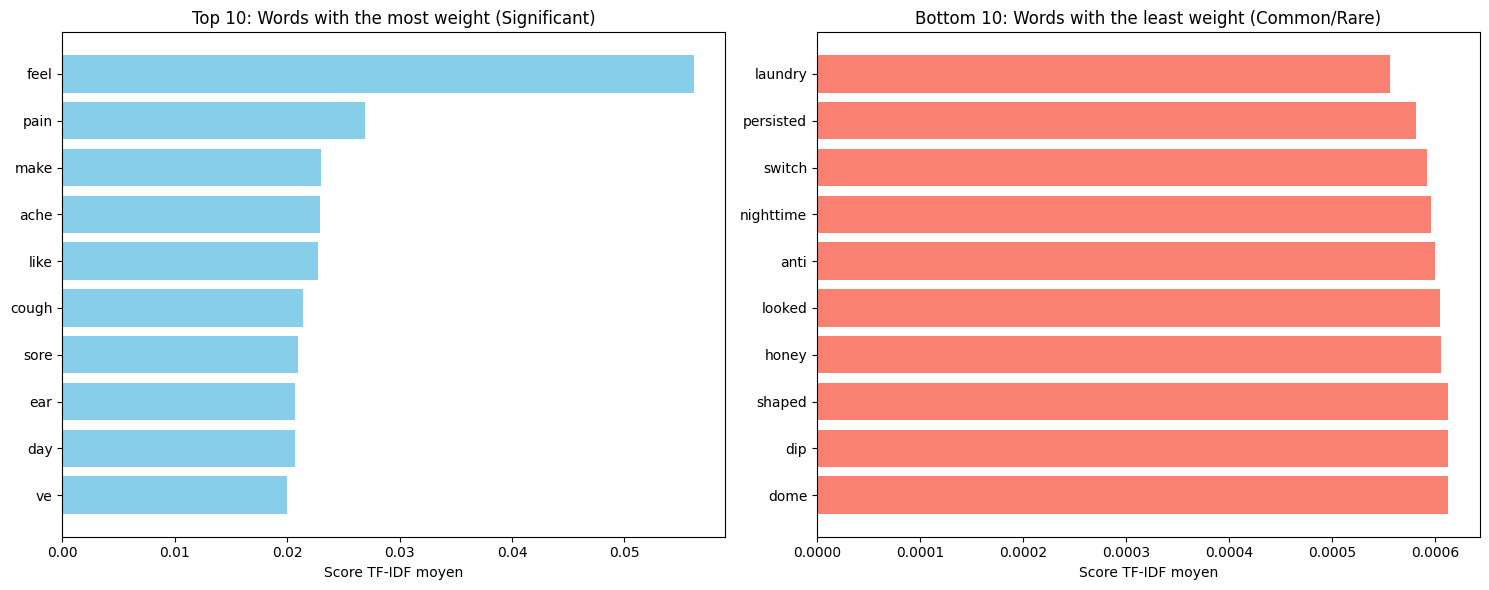

In [237]:
feature_names = vectorizer.get_feature_names_out()
mean_weights = np.asarray(X.mean(axis=0)).ravel()

df_weights = pd.DataFrame({'word': feature_names, 'weight': mean_weights})
df_top = df_weights.sort_values(by='weight', ascending=False).head(10)
df_bottom = df_weights.sort_values(by='weight', ascending=True).head(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.barh(df_top['word'], df_top['weight'], color='skyblue')
ax1.set_title('Top 10: Words with the most weight (Significant)')
ax1.invert_yaxis()
ax1.set_xlabel('Score TF-IDF moyen')

ax2.barh(df_bottom['word'], df_bottom['weight'], color='salmon')
ax2.set_title('Bottom 10: Words with the least weight (Common/Rare)')
ax2.invert_yaxis()
ax2.set_xlabel('Score TF-IDF moyen')

plt.tight_layout()
plt.show()

## Clustering of the data

In this section, we will perform data clustering. To do this, we will apply `K-Means` clustering methods.

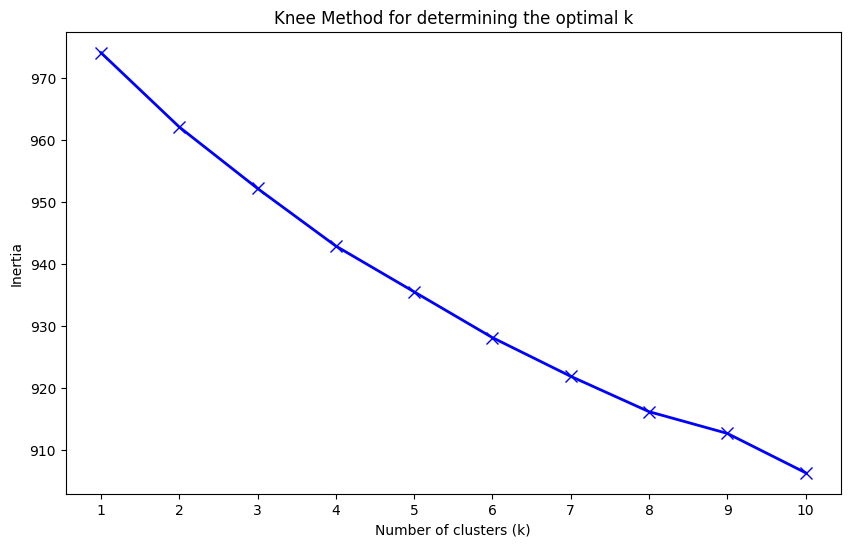

In [238]:
from sklearn.cluster import KMeans

inertie = []
K_range = range(1, 11)

for k in K_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertie.append(model.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(K_range, inertie, 'bx-', markersize=8, linewidth=2)
plt.xticks(K_range) 
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Knee Method for determining the optimal k')
plt.show()


### Conclusion

By observing the curve, we see a rapid slowdown starting from 9 clusters.Therefore, we will use 9 clusters to train our model.

In [239]:
kmeans_final = KMeans(n_clusters=9, random_state=42, n_init=10)

df_final['Cluster_Predit'] = kmeans_final.fit_predict(X)

print("Distribution of testimonies across the 9 clusters:")
print(df_final['Cluster_Predit'].value_counts().sort_index().to_string())

distances = kmeans_final.transform(X)

for i in range(9):
    indices_du_cluster = np.where(df_final['Cluster_Predit'] == i)[0]
    
    if len(indices_du_cluster) > 0:
        top_3_indices_relatifs = np.argsort(distances[indices_du_cluster, i])[:3]
        indices_finaux = indices_du_cluster[top_3_indices_relatifs]
        ids_bruts = df_final.iloc[indices_finaux]['ID'].tolist()
        print(f"CLUSTER {i} (IDs) : {list(ids_bruts)}")
    else:
        print(f"CLUSTER {i} : No items found")

print("\n" + "-"*60)

Distribution of testimonies across the 9 clusters:
Cluster_Predit
0     97
1    202
2     60
3     76
4    101
5     80
6    131
7     90
8    165
CLUSTER 0 (IDs) : [638, 75, 868]
CLUSTER 1 (IDs) : [974, 249, 250]
CLUSTER 2 (IDs) : [175, 939, 1008]
CLUSTER 3 (IDs) : [713, 901, 842]
CLUSTER 4 (IDs) : [757, 833, 383]
CLUSTER 5 (IDs) : [838, 246, 495]
CLUSTER 6 (IDs) : [535, 755, 995]
CLUSTER 7 (IDs) : [227, 211, 936]
CLUSTER 8 (IDs) : [198, 486, 724]

------------------------------------------------------------


## Clusters visualisations

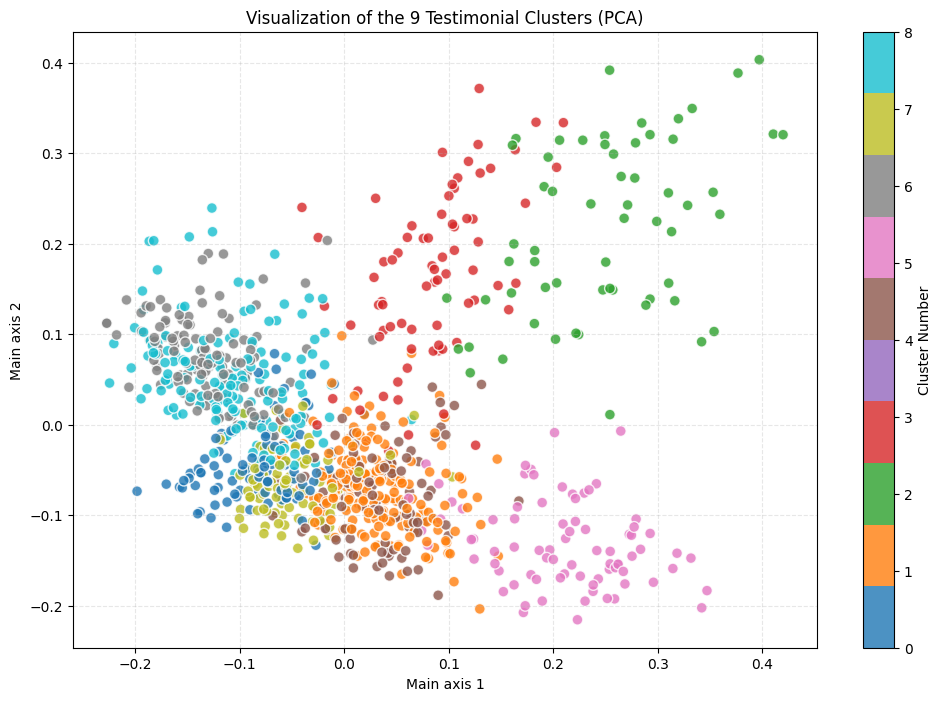

In [240]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
coords = pca.fit_transform(X.toarray())

clusters_couleurs = df_final['Cluster_Predit']

plt.figure(figsize=(12, 8))

scatter = plt.scatter(coords[:, 0], coords[:, 1], 
                      c=clusters_couleurs, 
                      cmap='tab10', 
                      alpha=0.8, 
                      edgecolors='w', 
                      s=60)

plt.title("Visualization of the 9 Testimonial Clusters (PCA)")
plt.xlabel("Main axis 1")
plt.ylabel("Main axis 2")

# Légende numérotée de 0 à 8
plt.colorbar(scatter, ticks=range(9), label="Cluster Number")
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()